# 03 · Stock trading costs and hedge-volatility error

**Objective:** measure how stock execution costs and an incorrect volatility used for hedge deltas change the three-name short-call portfolio's results.

The baseline contracts, quantities, **stock paths and opening premiums stay fixed**. The cost experiment changes only the stock trading charge. The hedge-volatility experiment changes only the volatility used for delta calculations, at a fixed trading charge. These experiments isolate implementation effects from a change in the option sale price.

The defaults use **5,000 correlated Q paths**, stock costs of **0, 1, 5 and 10 bp**, and hedge-volatility multipliers of **0.8, 1.0 and 1.2**. A final **10,000-path fresh-seed run** checks the pre-specified daily and five-session policies.

This completed notebook runs independently from a fresh kernel. Its model inputs load from the shared validated configuration used by notebook 02; experiment controls remain explicit. Inputs remain illustrative; quantities are share-equivalent short European call units, with zero dividends and constant financing. There is no exchange contract multiplier, option spread or margin constraint.

**Shared study inputs:** contract and scenario assumptions now load from `config/illustrative_study.json` through `load_named_inputs`. `Book` remains the validated model container. Change that file once to update the baseline across notebooks 00–03; policy/experiment controls stay explicit in each notebook. 


| Step | Purpose | Main functions/tools |
|---|---|---|
| 1–2 | Load packages and inspect named inputs | Dictionaries, `Book`, `initial_exposures` |
| 3 | Freeze the correlated baseline paths and premium | `simulate_paths`, source/input records |
| 4–5 | Vary stock costs and reconcile their financed effect | `hedge`, `summarize`, NumPy assertions |
| 6 | Compare daily and five-session means on matched paths | `paired_difference` |
| 7–8 | Vary hedge volatility while preserving option prices | `hedge(..., hedge_vols=...)` |
| 9 | Check fixed policies on a fresh larger sample | New seed, paired mean comparison |
| 10–11 | Interpret the results and record both runs | Calculated summaries, `provenance` |

All P&L statistics already include costs. Reporting those costs alongside net P&L does not mean subtracting them again. The paired intervals below concern **mean P&L differences**, not uncertainty in standard deviation or ES95.

## 1 · Connect to the project

Locate the project root and import the same pricing and accounting helpers used in the earlier notebooks. The kernel can start in either the project root or the notebook folder.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
while not (ROOT / 'src' / 'hedging_harness').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'hedging_harness').is_dir(), 'Open this notebook inside the repository.'
sys.path.insert(0, str(ROOT / 'src'))
from IPython.display import display
from hedging_harness.configuration import defaults, notebook_controls
from hedging_harness.notebook_support import verify_frozen_overlay, historical_root, historical_path


In [2]:
_controls = notebook_controls('03_cost_and_volatility_sensitivity')
from pathlib import Path
from hashlib import sha256
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src" / "hedging_harness" / "core.py").is_file():
    ROOT = ROOT.parent
assert (ROOT / "src" / "hedging_harness" / "core.py").is_file(), f"Wrong project root: {ROOT}"
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from hedging_harness import Book, simulate_paths, hedge, summarize, initial_exposures, provenance, paired_difference

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.2,
})
print(f"Project root: {ROOT}")



Project root: /Users/saireddivari/MonteCarloEvaluations


## 2 · Define the named inputs and experiment controls

The portfolio and scenario load from the same validated study file as notebook 02. The controls specify the complete comparison before any results are calculated:

- Each policy opens a delta hedge and liquidates it at expiry. Initial-only holds its first stock hedge until settlement.
- Costs are one-way basis points of absolute stock dollars traded, including entry and liquidation.
- `REFERENCE_COST_BPS` sets the common charge for hedge-volatility sensitivity and fresh-seed checks.
- A hedge-volatility multiplier is a **relative change**: 0.8 means 20% below the base volatility, not 20 percentage points below it.
- `VALIDATION_POLICIES` are fixed here, before the fresh run. No policy is selected by optimizing its sample result.

This exercise uses matching pricing and path volatilities at baseline. Changing the option's pricing volatility or its true path volatility would be a separate experiment.

In [3]:
from hedging_harness.study import load_named_inputs
option_portfolio, scenario, shared_config = load_named_inputs(
    ROOT / "config" / "illustrative_study.json"
)


POLICIES = _controls['POLICIES']
COST_GRID_BPS = _controls['COST_GRID_BPS']
REFERENCE_COST_BPS = _controls['REFERENCE_COST_BPS']
HEDGE_VOL_MULTIPLIERS = _controls['HEDGE_VOL_MULTIPLIERS']
SENSITIVITY_POLICIES = _controls['SENSITIVITY_POLICIES']
N_PATHS = shared_config["n_paths"]
SEED = shared_config["seed"]
AUDIT_PATH = _controls['AUDIT_PATH']
VALIDATION_N = _controls['VALIDATION_N']
VALIDATION_SEED = SEED + 1
VALIDATION_POLICIES = {name: POLICIES[name] for name in ("daily", "weekly")}

option_underlyings = list(option_portfolio)
assert set(scenario["path_vols"]) == set(option_underlyings)
assert isinstance(N_PATHS, int) and N_PATHS >= 2
assert 0 <= AUDIT_PATH < min(N_PATHS, VALIDATION_N)
assert VALIDATION_N >= 2 and VALIDATION_SEED != SEED
assert len(set(COST_GRID_BPS)) == len(COST_GRID_BPS)
assert 0.0 in COST_GRID_BPS and REFERENCE_COST_BPS in COST_GRID_BPS
assert all(np.isfinite(cost) and cost >= 0 for cost in COST_GRID_BPS)
assert len(set(HEDGE_VOL_MULTIPLIERS)) == len(HEDGE_VOL_MULTIPLIERS)
assert 1.0 in HEDGE_VOL_MULTIPLIERS
assert all(np.isfinite(multiplier) and multiplier > 0 for multiplier in HEDGE_VOL_MULTIPLIERS)
assert set(SENSITIVITY_POLICIES).issubset(POLICIES)

assumptions = pd.DataFrame.from_dict(option_portfolio, orient="index")
assumptions.index.name = "name"
for field in ("days_to_expiration", "days_in_trading_year", "risk_free_rate"):
    assert assumptions[field].nunique() == 1, f"The simulator requires one common {field}."
assumptions["call_units"] = assumptions["notional"] / assumptions["spot"]
assumptions["maturity_years"] = assumptions["days_to_expiration"] / assumptions["days_in_trading_year"]
assumptions["path_vol"] = pd.Series(scenario["path_vols"])
assert not assumptions.isna().any().any()
np.testing.assert_allclose(
    assumptions["pricing_vol"], assumptions["path_vol"],
    err_msg="Use matching pricing/path vols to isolate the hedge-volatility error in this experiment."
)

correlation_matrix = pd.DataFrame(
    np.eye(len(option_underlyings)), index=option_underlyings, columns=option_underlyings
)
seen_pairs = set()
for (name_a, name_b), value in scenario["correlations"].items():
    assert name_a in option_portfolio and name_b in option_portfolio and name_a != name_b
    assert np.isfinite(value) and -1 <= value <= 1
    pair = frozenset((name_a, name_b))
    assert pair not in seen_pairs
    seen_pairs.add(pair)
    correlation_matrix.loc[name_a, name_b] = value
    correlation_matrix.loc[name_b, name_a] = value
assert len(seen_pairs) == len(option_underlyings) * (len(option_underlyings) - 1) // 2
assert np.linalg.eigvalsh(correlation_matrix.to_numpy()).min() >= -1e-10

first_option = option_portfolio[option_underlyings[0]]
book = Book(
    names=tuple(option_underlyings),
    spots=tuple(option_portfolio[name]["spot"] for name in option_underlyings),
    strikes=tuple(option_portfolio[name]["strike"] for name in option_underlyings),
    notionals=tuple(option_portfolio[name]["notional"] for name in option_underlyings),
    pricing_vols=tuple(option_portfolio[name]["pricing_vol"] for name in option_underlyings),
    steps=first_option["days_to_expiration"],
    sessions_per_year=first_option["days_in_trading_year"],
    rate=first_option["risk_free_rate"],
)
simulation_scenario = {
    "path_vols": [scenario["path_vols"][name] for name in option_underlyings],
    "correlation": correlation_matrix.loc[option_underlyings, option_underlyings].to_numpy().tolist(),
}
opening_exposures = initial_exposures(book)
display(assumptions)
print("Fixed opening premium and base exposures:")
display(opening_exposures.round(4))



,spot,strike,notional,pricing_vol,days_to_expiration,days_in_trading_year,risk_free_rate,call_units,maturity_years,path_vol
name,,,,,,,,,,
JPM,100.0,100.0,100000.0,0.22,63,252,0.04,1000.0,0.25,0.22
PNC,100.0,100.0,100000.0,0.28,63,252,0.04,1000.0,0.25,0.28
GS,100.0,100.0,100000.0,0.26,63,252,0.04,1000.0,0.25,0.26


Fixed opening premium and base exposures:


,short_call_units,initial_premium,hedge_shares,option_dollar_delta,option_gamma_pnl_for_1pct_move,option_vega_per_vol_point
name,,,,,,
JPM,1000.0,4879.8441,558.0034,-55800.3423,-17.9417,-197.3591
PNC,1000.0,6064.5144,556.2343,-55623.4308,-14.1062,-197.4862
GS,1000.0,5669.5521,556.4296,-55642.9617,-15.1902,-197.4723


## 3 · Freeze the correlated paths and pricing inputs

Generate the same correlated baseline histories as notebook 02 using the same name order, inputs, dimensions and seed. Every baseline cost and hedge-volatility case receives this exact array.

A hash identifies the realized paths and is checked again after the experiments. The opening premium comes from the fixed book pricing volatilities. `hedge_vols` changes the stock hedge rule only; it does not change the sale premium or the accounting volatility used for interim option marks.

In [4]:
paths = simulate_paths(book, **simulation_scenario, n_paths=N_PATHS, seed=SEED)
assert paths.shape == (N_PATHS, book.steps + 1, len(book.names))
assert np.isfinite(paths).all() and (paths > 0).all()
np.testing.assert_allclose(paths[:, 0, :], np.broadcast_to(book.spots, (N_PATHS, len(book.names))))
base_paths_sha256 = sha256(paths.tobytes()).hexdigest()
premium_reference = opening_exposures["initial_premium"].to_numpy()
print(f"Baseline paths: {paths.shape}; seed: {SEED}")
print(f"Total fixed model premium: ${premium_reference.sum():,.4f}")
print(f"Path-array SHA256: {base_paths_sha256}")



Baseline paths: (5000, 64, 3); seed: 20261105
Total fixed model premium: $16,613.9107
Path-array SHA256: 1eaf5cd38e9e7c4dbad83dc3bc38f725195deb57a53c25cffc7fc9d2d57a6fb3


## 4 · Vary stock trading costs

Evaluate all four hedge policies at every charge in `COST_GRID_BPS`. Paths, contracts, pricing volatility and hedge volatility stay fixed. The same policy therefore trades the same stock quantities at every cost level; only cash and resulting net P&L change.

The table shows portfolio outcomes, computed from each path's summed name-level P&L. `mean_se` measures uncertainty in the mean; `pnl_std` describes economic variability. ES95 is minus the mean of the worst 5% of outcomes, rounded up to a whole observation count.

In [5]:
cost_results = {}
cost_rows = []
for cost in COST_GRID_BPS:
    for policy, interval in POLICIES.items():
        result = hedge(book, paths, hedge_every=interval, cost_bps=cost, audit_path=AUDIT_PATH)
        cost_results[cost, policy] = result
        cost_rows.append({"cost_bps": cost, "policy": policy, **summarize(result).loc["Portfolio"].to_dict()})
cost_table = pd.DataFrame(cost_rows)
cost_summary = cost_table.set_index(["cost_bps", "policy"])
display(cost_summary[[
    "mean_pnl", "mean_se", "pnl_std", "loss_es95",
    "mean_cost", "mean_financed_cost", "mean_turnover"
]].round(4))



mean_pnl   mean_se    pnl_std   loss_es95  mean_cost  \
cost_bps policy                                                                
0.0      initial_only    59.9627  123.5524  8736.4710  23544.9116     0.0000   
         daily            3.4253   17.0230  1203.7099   2692.1777     0.0000   
         two_day         -4.2497   23.5055  1662.0904   3832.9448     0.0000   
         weekly         -42.7499   36.2595  2563.9360   5995.6968     0.0000   
1.0      initial_only    26.1889  123.5557  8736.7105  23579.9625    33.6058   
         daily         -105.5146   17.0670  1206.8203   2821.0977   108.3990   
         two_day        -91.6868   23.5505  1665.2727   3936.7460    87.0088   
         weekly        -110.0779   36.3031  2567.0191   6076.9866    67.0009   
5.0      initial_only  -108.9060  123.5693  8737.6723  23720.1810   168.0291   
         daily         -541.2742   17.3022  1223.4530   3342.1034   541.9950   
         two_day       -441.4354   23.7593  1680.0367   4353.3252   435.0440   
         weekly        -379.3899   36.4895  2580.1970   6402.6882   335.0045   
10.0     initial_only  -277.7746  123.5865  8738.8833  23895.4543   336.0583   
         daily        -1085.9737   17.7248  1253.3296   4004.4725  1083.9900   
         two_day       -878.6211   24.0836  1702.9655   4879.9106   870.0879   
         weekly        -716.0299   36.7490  2598.5467   6811.4457   670.0091   

                       mean_financed_cost  mean_turnover  
cost_bps policy                                           
0.0      initial_only              0.0000   3.360583e+05  
         daily                     0.0000   1.083990e+06  
         two_day                   0.0000   8.700879e+05  
         weekly                    0.0000   6.700091e+05  
1.0      initial_only             33.7737   3.360583e+05  
         daily                   108.9399   1.083990e+06  
         two_day                  87.4371   8.700879e+05  
         weekly                   67.3280   6.700091e+05  
5.0      initial_only            168.8687   3.360583e+05  
         daily                   544.6995   1.083990e+06  
         two_day                 437.1857   8.700879e+05  
         weekly                  336.6400   6.700091e+05  
10.0     initial_only            337.7373   3.360583e+05  
         daily                  1089.3990   1.083990e+06  
         two_day                 874.3714   8.700879e+05  
         weekly                  673.2800   6.700091e+05

### Reconcile costs, trades and net P&L

For each policy, compare the costly result with its zero-cost counterpart on the same paths. For every outcome and name,

$$\text{zero-cost P\&L}-\text{costly P\&L}=\text{financed stock costs}.$$

Nominal costs add fees at their trade dates. Financed costs accumulate those amounts to expiry at the financing rate. The latter captures the complete terminal cash impact. Net P&L already includes that impact.

The checks also confirm identical turnover, trade counts, audited share holdings and opening premiums across cost levels.

In [6]:
cost_check_rows = []
for (cost, policy), result in cost_results.items():
    reference = cost_results[0.0, policy]
    residual = reference.terminal_pnl - result.terminal_pnl - result.financed_costs
    np.testing.assert_allclose(residual, 0.0, atol=1e-8, rtol=0)
    np.testing.assert_allclose(reference.turnover, result.turnover, atol=1e-9, rtol=0)
    np.testing.assert_array_equal(reference.trade_counts, result.trade_counts)
    np.testing.assert_allclose(reference.ledger["shares_after"], result.ledger["shares_after"])
    opening = result.ledger.loc[result.ledger["step"].eq(0)].set_index("name").reindex(book.names)
    np.testing.assert_allclose(opening["premium_received"], premium_reference)
    cost_check_rows.append({
        "cost_bps": cost, "policy": policy,
        "max_financed_cost_identity_residual": np.abs(residual).max(),
        "mean_financed_portfolio_cost": result.financed_costs.sum(axis=1).mean(),
    })
cost_checks = pd.DataFrame(cost_check_rows).set_index(["cost_bps", "policy"])
display(cost_checks.round(8))
print("Financed-cost identities, fixed premiums and unchanged-trade checks passed for every cost case.")



max_financed_cost_identity_residual  \
cost_bps policy                                              
0.0      initial_only                                  0.0   
         daily                                         0.0   
         two_day                                       0.0   
         weekly                                        0.0   
1.0      initial_only                                  0.0   
         daily                                         0.0   
         two_day                                       0.0   
         weekly                                        0.0   
5.0      initial_only                                  0.0   
         daily                                         0.0   
         two_day                                       0.0   
         weekly                                        0.0   
10.0     initial_only                                  0.0   
         daily                                         0.0   
         two_day                                       0.0   
         weekly                                        0.0   

                       mean_financed_portfolio_cost  
cost_bps policy                                      
0.0      initial_only                      0.000000  
         daily                             0.000000  
         two_day                           0.000000  
         weekly                            0.000000  
1.0      initial_only                     33.773731  
         daily                           108.939904  
         two_day                          87.437144  
         weekly                           67.328003  
5.0      initial_only                    168.868655  
         daily                           544.699518  
         two_day                         437.185721  
         weekly                          336.640017  
10.0     initial_only                    337.737310  
         daily                          1089.399036  
         two_day                         874.371442  
         weekly                          673.280035

Financed-cost identities, fixed premiums and unchanged-trade checks passed for every cost case.


## 5 · Compare risk against implementation cost

The charts show portfolio risk versus **mean financed stock cost**, matching the terminal-P&L accounting. Each point is labelled with its assumed basis-point charge. The tables retain initial-only; the charts focus on the three rebalanced policies because initial-only's much larger risk would compress their scale.

A point with lower tail risk can require more trading and a larger cost drag. No single point is universally best without a specified loss objective and budget. These curves are descriptive comparisons, rather than a policy optimization.

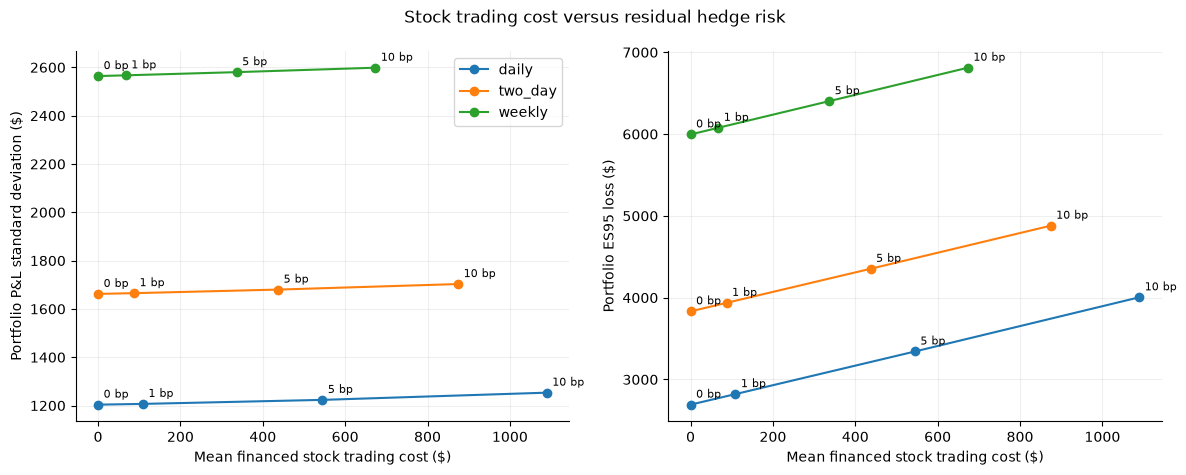

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for policy in SENSITIVITY_POLICIES:
    sub = cost_table.loc[cost_table["policy"].eq(policy)].sort_values("cost_bps")
    for ax, metric in zip(axes, ["pnl_std", "loss_es95"]):
        ax.plot(sub["mean_financed_cost"], sub[metric], marker="o", label=policy)
        for _, row in sub.iterrows():
            ax.annotate(f"{row['cost_bps']:g} bp", (row["mean_financed_cost"], row[metric]),
                        xytext=(4, 5), textcoords="offset points", fontsize=8)
        ax.set_xlabel("Mean financed stock trading cost ($)")
axes[0].set_ylabel("Portfolio P&L standard deviation ($)")
axes[1].set_ylabel("Portfolio ES95 loss ($)")
axes[0].legend()
fig.suptitle("Stock trading cost versus residual hedge risk")
fig.tight_layout()
plt.show()



## 6 · Compare daily and five-session policies on matched paths

`paired_difference(daily, weekly)` computes the portfolio P&L difference **within each simulated outcome**, then estimates its mean and standard error. A negative mean means daily hedging produced lower net P&L on average in that sample.

The approximate interval is `mean difference ± 1.96 × paired SE`. It concerns the mean difference only. The risk-reduction columns report observed standard deviation and ES95 changes; the paired interval is not an interval for either risk statistic.

Costs can make mean P&L comparisons differ from risk comparisons: daily hedging can reduce downside variability while incurring more trading costs.

In [8]:
paired_rows = []
for cost in COST_GRID_BPS:
    daily_row = cost_summary.loc[(cost, "daily")]
    weekly_row = cost_summary.loc[(cost, "weekly")]
    comparison = paired_difference(cost_results[cost, "daily"], cost_results[cost, "weekly"])
    paired_rows.append({
        "cost_bps": cost,
        **comparison,
        "daily_std_reduction_vs_weekly_pct": 100 * (1 - daily_row["pnl_std"] / weekly_row["pnl_std"]),
        "daily_ES95_reduction_vs_weekly": weekly_row["loss_es95"] - daily_row["loss_es95"],
        "daily_extra_financed_cost": daily_row["mean_financed_cost"] - weekly_row["mean_financed_cost"],
        "mean_interval_excludes_zero": comparison["mc_95_low"] > 0 or comparison["mc_95_high"] < 0,
    })
paired_policy_comparisons = pd.DataFrame(paired_rows).set_index("cost_bps")
display(paired_policy_comparisons.round(4))



,mean_difference,paired_se,mc_95_low,mc_95_high,daily_std_reduction_vs_weekly_pct,daily_ES95_reduction_vs_weekly,daily_extra_financed_cost,mean_interval_excludes_zero
cost_bps,,,,,,,,
0.0,46.1752,32.2428,-17.0207,109.3711,53.0523,3303.5191,0.0000,False
1.0,4.5633,32.3549,-58.8522,67.9788,52.9875,3255.8889,41.6119,False
5.0,-161.8843,32.8114,-226.1947,-97.5739,52.5830,3060.5847,208.0595,True
10.0,-369.9438,33.4002,-435.4082,-304.4794,51.7681,2806.9732,416.1190,True


## 7 · Vary the volatility used for hedge deltas

Multiply each base pricing volatility by 0.8, 1.0 or 1.2 **only when calculating hedge delta**. For example, a base volatility of 22% becomes 17.6%, 22% or 26.4%.

Path volatility, contracts, quantities, rates, opening option premium and interim option-marking volatility remain fixed. This isolates hedge misspecification. An incorrect hedge volatility changes share holdings, residual risk, turnover and consequently costs; it does not create a different option sale price.

All cases use `REFERENCE_COST_BPS`. The multiplier-1 results reuse the existing cost experiment at that charge, ensuring an identical baseline.

In [9]:
hedge_vol_inputs = pd.DataFrame(
    [np.asarray(book.pricing_vols) * multiplier for multiplier in HEDGE_VOL_MULTIPLIERS],
    index=pd.Index(HEDGE_VOL_MULTIPLIERS, name="hedge_vol_multiplier"), columns=book.names,
)
print("Actual annual hedge volatilities (decimal units):")
display(hedge_vol_inputs)

vol_results = {}
vol_rows = []
for multiplier in HEDGE_VOL_MULTIPLIERS:
    for policy in SENSITIVITY_POLICIES:
        if multiplier == 1.0:
            result = cost_results[REFERENCE_COST_BPS, policy]
        else:
            result = hedge(
                book, paths, hedge_every=POLICIES[policy], cost_bps=REFERENCE_COST_BPS,
                hedge_vols=np.asarray(book.pricing_vols) * multiplier, audit_path=AUDIT_PATH,
            )
        vol_results[multiplier, policy] = result
        vol_rows.append({
            "hedge_vol_multiplier": multiplier, "policy": policy,
            **summarize(result).loc["Portfolio"].to_dict(),
        })
vol_table = pd.DataFrame(vol_rows)
vol_summary = vol_table.set_index(["hedge_vol_multiplier", "policy"])
display(vol_summary[[
    "mean_pnl", "mean_se", "pnl_std", "loss_es95", "mean_cost", "mean_financed_cost", "mean_turnover"
]].round(4))



Actual annual hedge volatilities (decimal units):


,JPM,PNC,GS
hedge_vol_multiplier,,,
0.8,0.176,0.224,0.208
1.0,0.220,0.280,0.260
1.2,0.264,0.336,0.312


mean_pnl  mean_se    pnl_std  loss_es95  \
hedge_vol_multiplier policy                                             
0.8                  daily   -576.5058  22.4278  1585.8877  4440.2808   
                     two_day -463.3206  27.6278  1953.5784  5365.0739   
                     weekly  -395.3175  38.9800  2756.2998  7373.0368   
1.0                  daily   -541.2742  17.3022  1223.4530  3342.1034   
                     two_day -441.4354  23.7593  1680.0367  4353.3252   
                     weekly  -379.3899  36.4895  2580.1970  6402.6882   
1.2                  daily   -510.5013  19.6251  1387.7046  3177.9979   
                     two_day -421.6039  25.5256  1804.9324  4084.2971   
                     weekly  -363.4353  37.6974  2665.6088  6004.6123   

                              mean_cost  mean_financed_cost  mean_turnover  
hedge_vol_multiplier policy                                                 
0.8                  daily     582.7508            585.7396   1.165502e+06  
                     two_day   463.3239            465.6640   9.266479e+05  
                     weekly    352.3611            354.1170   7.047222e+05  
1.0                  daily     541.9950            544.6995   1.083990e+06  
                     two_day   435.0440            437.1857   8.700879e+05  
                     weekly    335.0045            336.6400   6.700091e+05  
1.2                  daily     508.9413            511.4265   1.017883e+06  
                     two_day   412.2623            414.2518   8.245245e+05  
                     weekly    321.0481            322.5919   6.420962e+05

## 8 · Verify the fixed-premium experiment and compare outcomes

For every volatility/policy case, check the opening premium, each audited option-liability mark, observed stock prices and expiry payoff against the multiplier-1 reference. Only the hedge holdings and their resulting cash flows are allowed to change.

The paired comparisons below subtract the **correct-volatility** result from the changed-volatility result on the same paths. A negative mean difference indicates lower average net P&L relative to the reference. ES95 differences are displayed separately and have no confidence interval here.

Opening premiums remain fixed while hedge shares change:


premium_received  initial_hedge_shares
hedge_vol_multiplier name                                        
0.8                  JPM        4879.844122            562.628326
                     PNC        6064.514436            557.757353
                     GS         5669.552132            558.889322
1.0                  JPM        4879.844122            558.003423
                     PNC        6064.514436            556.234308
                     GS         5669.552132            556.429617
1.2                  JPM        4879.844122            556.364252
                     PNC        6064.514436            557.061746
                     GS         5669.552132            556.500504

Changed hedge volatility minus correct-volatility reference:


mean_difference  paired_se  mc_95_low  \
hedge_vol_multiplier policy                                           
0.8                  daily           -35.2316    13.0450   -60.7998   
                     two_day         -21.8852    12.9971   -47.3594   
                     weekly          -15.9276    12.9277   -41.2659   
1.2                  daily            30.7729    10.6981     9.8047   
                     two_day          19.8315    10.6688    -1.0794   
                     weekly           15.9546    10.6179    -4.8564   

                              mc_95_high  ES95_difference_vs_correct_vol  \
hedge_vol_multiplier policy                                                
0.8                  daily       -9.6633                       1098.1774   
                     two_day      3.5891                       1011.7487   
                     weekly       9.4107                        970.3486   
1.2                  daily       51.7411                       -164.1055   
                     two_day     40.7425                       -269.0281   
                     weekly      36.7657                       -398.0759   

                              mean_interval_excludes_zero  
hedge_vol_multiplier policy                                
0.8                  daily                           True  
                     two_day                        False  
                     weekly                         False  
1.2                  daily                           True  
                     two_day                        False  
                     weekly                         False

Fixed-premium, fixed-mark, fixed-settlement and unchanged-path checks passed.


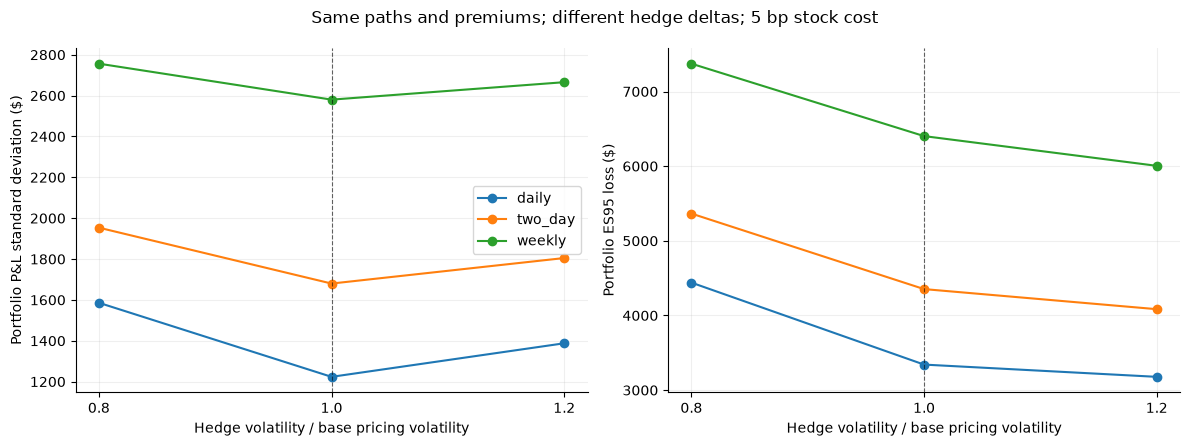

In [10]:
vol_comparison_rows = []
vol_opening_rows = []
for (multiplier, policy), result in vol_results.items():
    reference = vol_results[1.0, policy]
    opening = result.ledger.loc[result.ledger["step"].eq(0)].set_index("name").reindex(book.names)
    np.testing.assert_allclose(opening["premium_received"], premium_reference)
    for column in ("spot", "option_liability", "payoff_paid"):
        np.testing.assert_allclose(result.ledger[column], reference.ledger[column])
    for name in book.names:
        if policy == "daily":
            vol_opening_rows.append({
                "hedge_vol_multiplier": multiplier, "name": name,
                "premium_received": opening.loc[name, "premium_received"],
                "initial_hedge_shares": opening.loc[name, "shares_after"],
            })
    if multiplier != 1.0:
        comparison = paired_difference(result, reference)
        vol_comparison_rows.append({
            "hedge_vol_multiplier": multiplier, "policy": policy,
            **comparison,
            "ES95_difference_vs_correct_vol": (
                vol_summary.loc[(multiplier, policy), "loss_es95"] - vol_summary.loc[(1.0, policy), "loss_es95"]
            ),
            "mean_interval_excludes_zero": comparison["mc_95_low"] > 0 or comparison["mc_95_high"] < 0,
        })
vol_opening_comparison = pd.DataFrame(vol_opening_rows).set_index(["hedge_vol_multiplier", "name"])
vol_comparisons = pd.DataFrame(vol_comparison_rows).set_index(["hedge_vol_multiplier", "policy"])
print("Opening premiums remain fixed while hedge shares change:")
display(vol_opening_comparison.round(6))
print("Changed hedge volatility minus correct-volatility reference:")
display(vol_comparisons.round(4))
assert sha256(paths.tobytes()).hexdigest() == base_paths_sha256
print("Fixed-premium, fixed-mark, fixed-settlement and unchanged-path checks passed.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for policy in SENSITIVITY_POLICIES:
    sub = vol_table.loc[vol_table["policy"].eq(policy)].sort_values("hedge_vol_multiplier")
    for ax, metric in zip(axes, ["pnl_std", "loss_es95"]):
        ax.plot(sub["hedge_vol_multiplier"], sub[metric], marker="o", label=policy)
        ax.set_xlabel("Hedge volatility / base pricing volatility")
for ax in axes:
    ax.axvline(1.0, color="black", linestyle="--", linewidth=0.8, alpha=0.6)
    ax.set_xticks(HEDGE_VOL_MULTIPLIERS)
axes[0].set_ylabel("Portfolio P&L standard deviation ($)")
axes[1].set_ylabel("Portfolio ES95 loss ($)")
axes[0].legend()
fig.suptitle(f"Same paths and premiums; different hedge deltas; {REFERENCE_COST_BPS:g} bp stock cost")
fig.tight_layout()
plt.show()



## 9 · Check fixed policies on a fresh larger sample

Generate 10,000 fresh outcomes with `VALIDATION_SEED` and the same contracts, marginal inputs and correlation matrix. Apply the daily and five-session rules specified in the input cell, at the reference cost and correct hedge volatility.

Within each run, the two policies share paths and their mean difference can be paired. The baseline and fresh runs are separate samples, so no pairing is applied across them. This checks simulation stability, rather than external market validity or an optimized policy choice.

The displayed mean intervals are approximate Monte Carlo intervals. No corresponding precision claim is made for ES95 or the volatility-sensitivity rankings.

In [11]:
fresh = simulate_paths(book, **simulation_scenario, n_paths=VALIDATION_N, seed=VALIDATION_SEED)
assert fresh.shape == (VALIDATION_N, book.steps + 1, len(book.names))
validation_paths_sha256 = sha256(fresh.tobytes()).hexdigest()
validation_results = {
    policy: hedge(book, fresh, hedge_every=interval, cost_bps=REFERENCE_COST_BPS, audit_path=AUDIT_PATH)
    for policy, interval in VALIDATION_POLICIES.items()
}
validation_table = pd.DataFrame({
    policy: summarize(result).loc["Portfolio"] for policy, result in validation_results.items()
}).T
validation_table.index.name = "policy"
validation_paired = paired_difference(validation_results["daily"], validation_results["weekly"])

baseline_comparison = cost_summary.xs(REFERENCE_COST_BPS, level="cost_bps").loc[list(VALIDATION_POLICIES)]
validation_comparison = pd.concat({
    "baseline": baseline_comparison,
    "fresh_seed": validation_table,
}, names=["run", "policy"])
display(validation_comparison[[
    "paths", "mean_pnl", "mean_se", "pnl_std", "loss_es95", "mean_financed_cost"
]].round(4))
paired_run_comparison = pd.DataFrame({
    "baseline": paired_difference(cost_results[REFERENCE_COST_BPS, "daily"], cost_results[REFERENCE_COST_BPS, "weekly"]),
    "fresh_seed": validation_paired,
}).T
paired_run_comparison.index.name = "run"
print("Daily minus five-session mean net P&L; paired within each run:")
display(paired_run_comparison.round(4))
print(f"Fresh seed: {VALIDATION_SEED}; outcomes: {VALIDATION_N:,}; fixed stock cost: {REFERENCE_COST_BPS:g} bp")



paths  mean_pnl  mean_se    pnl_std  loss_es95  \
run        policy                                                     
baseline   daily    5000.0 -541.2742  17.3022  1223.4530  3342.1034   
           weekly   5000.0 -379.3899  36.4895  2580.1970  6402.6882   
fresh_seed daily   10000.0 -534.3658  12.0537  1205.3684  3275.3510   
           weekly  10000.0 -352.5810  26.0084  2600.8389  6345.8810   

                   mean_financed_cost  
run        policy                      
baseline   daily             544.6995  
           weekly            336.6400  
fresh_seed daily             543.6609  
           weekly            335.5759

Daily minus five-session mean net P&L; paired within each run:


,mean_difference,paired_se,mc_95_low,mc_95_high
run,,,,
baseline,-161.8843,32.8114,-226.1947,-97.5739
fresh_seed,-181.7848,23.3001,-227.4531,-136.1165


Fresh seed: 20261106; outcomes: 10,000; fixed stock cost: 5 bp


### Visualize uncertainty in the paired mean difference

Each point is the estimated **daily minus five-session mean net P&L**. The horizontal interval is its approximate 95% Monte Carlo interval. This plot concerns the average outcome, while the preceding tables separately report the dispersion and tail losses of individual trading outcomes.

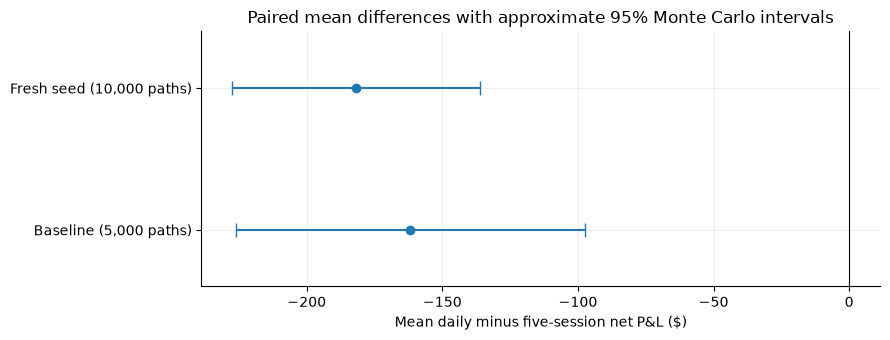

In [12]:
centers = paired_run_comparison["mean_difference"].to_numpy()
left_errors = centers - paired_run_comparison["mc_95_low"].to_numpy()
right_errors = paired_run_comparison["mc_95_high"].to_numpy() - centers
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.errorbar(centers, np.arange(len(centers)), xerr=np.vstack([left_errors, right_errors]),
            fmt="o", capsize=5, color="tab:blue")
ax.set_yticks(np.arange(len(centers)), [f"Baseline ({N_PATHS:,} paths)", f"Fresh seed ({VALIDATION_N:,} paths)"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Mean daily minus five-session net P&L ($)", title="Paired mean differences with approximate 95% Monte Carlo intervals")
ax.margins(y=0.4)
fig.tight_layout()
plt.show()



## 10 · Interpret the completed experiments

The calculated summary below reports how much daily hedging reduced risk relative to five-session hedging at the reference charge, and how its mean net P&L compared. The earlier cost and volatility tables show how those conclusions vary across the pre-specified assumptions.

A mean interval excluding zero identifies a difference large relative to its estimated Monte Carlo mean uncertainty in that comparison. It does not establish precision for ES95, economic optimality or a market trading edge.

Under the matched Q pricing/path model, a different predictable stock hedge changes risk and turnover without manufacturing a new option-pricing edge. With costs, expected net outcomes also reflect implementation drag. The experiments do not include real quotes, stochastic volatility, jumps, option spreads, dividends, margin or early exercise.

In [13]:
conclusion_rows = []
for run, table in [("baseline", baseline_comparison), ("fresh_seed", validation_table)]:
    daily = table.loc["daily"]
    weekly = table.loc["weekly"]
    paired = paired_run_comparison.loc[run]
    conclusion_rows.append({
        "run": run,
        "daily_std_reduction_vs_weekly_pct": 100 * (1 - daily["pnl_std"] / weekly["pnl_std"]),
        "daily_ES95_reduction_vs_weekly": weekly["loss_es95"] - daily["loss_es95"],
        "daily_minus_weekly_mean_PnL": paired["mean_difference"],
        "paired_mean_SE": paired["paired_se"],
        "mean_interval_excludes_zero": paired["mc_95_low"] > 0 or paired["mc_95_high"] < 0,
    })
conclusions = pd.DataFrame(conclusion_rows).set_index("run")
display(conclusions.round(4))
print("Portfolio ES95 by hedge-volatility multiplier:")
display(vol_table.pivot(index="hedge_vol_multiplier", columns="policy", values="loss_es95").round(4))
print("No policy was optimized or selected from these sample outcomes.")



,daily_std_reduction_vs_weekly_pct,daily_ES95_reduction_vs_weekly,daily_minus_weekly_mean_PnL,paired_mean_SE,mean_interval_excludes_zero
run,,,,,
baseline,52.5830,3060.5847,-161.8843,32.8114,True
fresh_seed,53.6546,3070.5300,-181.7848,23.3001,True


Portfolio ES95 by hedge-volatility multiplier:


policy,daily,two_day,weekly
hedge_vol_multiplier,,,
0.8,4440.2808,5365.0739,7373.0368
1.0,3342.1034,4353.3252,6402.6882
1.2,3177.9979,4084.2971,6004.6123


No policy was optimized or selected from these sample outcomes.


## 11 · Record both runs and all sensitivity assumptions

The baseline record includes the named portfolio, correlation scenario, cost grid, hedge-volatility grid, actual hedge volatilities, policies, audit path and realized-path hash. A nested validation record captures the separate seed, sample size, fixed policies and path hash used for the fresh run.

Runtime versions, source-file hashes and the notebook code hash make the implementation traceable. Hashing the paths again confirms that none of the hedge experiments modified the baseline or fresh price arrays. The record is displayed here without writing a separate export.

In [14]:
assert sha256(paths.tobytes()).hexdigest() == base_paths_sha256
assert sha256(fresh.tobytes()).hexdigest() == validation_paths_sha256

validation_record = provenance(book, simulation_scenario, VALIDATION_SEED, VALIDATION_N)
validation_record["policies"] = VALIDATION_POLICIES
validation_record["cost_bps"] = REFERENCE_COST_BPS
validation_record["hedge_vols"] = list(book.pricing_vols)
validation_record["paths_sha256"] = validation_paths_sha256

run_record = provenance(book, simulation_scenario, SEED, N_PATHS)
run_record["option_kind"] = "European call"
run_record["position_side"] = "short"
run_record["option_portfolio"] = option_portfolio
run_record["named_scenario"] = {
    "path_vols": scenario["path_vols"],
    "correlations": [
        {"name_a": name_a, "name_b": name_b, "correlation": value}
        for (name_a, name_b), value in scenario["correlations"].items()
    ],
}
run_record["policies"] = POLICIES
run_record["cost_grid_bps"] = COST_GRID_BPS
run_record["reference_cost_bps"] = REFERENCE_COST_BPS
run_record["hedge_volatility_cases"] = [
    {"multiplier": multiplier, "hedge_vols": (np.asarray(book.pricing_vols) * multiplier).tolist()}
    for multiplier in HEDGE_VOL_MULTIPLIERS
]
run_record["sensitivity_policies"] = SENSITIVITY_POLICIES
run_record["audit_path"] = AUDIT_PATH
run_record["paths_sha256"] = base_paths_sha256
run_record["opening_premium_by_name"] = dict(zip(book.names, premium_reference.tolist()))
run_record["validation_run"] = validation_record
run_record["input_source"] = "Shared validated config/illustrative_study.json; notebook controls remain explicit."
run_record["python_executable"] = sys.executable
notebook_path = ROOT / "notebooks" / "03_cost_and_volatility_sensitivity.ipynb"
notebook_source = json.loads(notebook_path.read_text())
code_text = "\n\n".join(
    "".join(cell["source"]) for cell in notebook_source["cells"] if cell["cell_type"] == "code"
)
run_record["notebook_code_sha256"] = sha256(code_text.encode()).hexdigest()
run_record["shared_input_source"] = shared_config["shared_input_source"]
print(json.dumps(run_record, indent=2))


{
  "book": {
    "names": [
      "JPM",
      "PNC",
      "GS"
    ],
    "spots": [
      100.0,
      100.0,
      100.0
    ],
    "strikes": [
      100.0,
      100.0,
      100.0
    ],
    "notionals": [
      100000.0,
      100000.0,
      100000.0
    ],
    "pricing_vols": [
      0.22,
      0.28,
      0.26
    ],
    "steps": 63,
    "sessions_per_year": 252,
    "rate": 0.04
  },
  "scenario": {
    "path_vols": [
      0.22,
      0.28,
      0.26
    ],
    "correlation": [
      [
        1.0,
        0.65,
        0.7
      ],
      [
        0.65,
        1.0,
        0.55
      ],
      [
        0.7,
        0.55,
        1.0
      ]
    ]
  },
  "seed": 20261105,
  "n_paths": 5000,
  "measure": "Q; drift equals constant financing rate; no dividends",
  "versions": {
    "python": "3.14.8",
    "numpy": "2.5.4",
    "scipy": "1.18.1",
    "pandas": "3.1.1"
  },
  "source_sha256": {
    "src/BlackScholes_Functions/BlackScholes_D1D2_Price_Payoff_Greeks.py": "7a96

## What the completed study establishes

Notebook 00 defines and checks the model inputs and stock paths. Notebook 01 reconciles a single option's stock/cash ledger. Notebook 02 combines the three names and compares dependence and hedge frequency. This notebook adds stock costs, hedge-volatility errors and a fresh-sample check of fixed policies.

The cost identities reconcile path by path, and the hedge-volatility comparisons preserve the opening premiums, option marks, terminal payoffs and realized stock paths. Tables and figures distinguish risk reduction from cost drag and uncertainty in mean comparisons.

Future work can introduce dated market inputs, explicit policy objectives, fresh evaluation scenarios, stochastic volatility or jumps, and the market-accounting features required by a listed-option replay. The current results remain conditional on the illustrative Q-model assumptions.